# PRACTICA 1 RECOMMENDATION SYSTEMS

In [2]:
import pandas as pd
import matplotlib.pyplot as plt

In [3]:
#carga de archivos

ratings = pd.read_csv(
    'file.tsv',
    sep='\t',
    names=['user_id', 'item_id', 'rating', 'timestamp']
)

movies = pd.read_csv('Movie_Id_Titles.csv')

In [4]:
ratings.head()

,user_id,item_id,rating,timestamp
0,0,50,5,881250949
1,0,172,5,881250949
2,0,133,1,881250949
3,196,242,3,881250949
4,186,302,3,891717742


In [5]:
movies.head()

,item_id,title
0,1,Toy Story (1995)
1,2,GoldenEye (1995)
2,3,Four Rooms (1995)
3,4,Get Shorty (1995)
4,5,Copycat (1995)


In [6]:
print("Número de valoraciones:", ratings.shape[0])
print("Número de películas:", movies.shape[0])
print("Número de usuarios:", ratings['user_id'].nunique())

Número de valoraciones: 100003
Número de películas: 1682
Número de usuarios: 944


In [7]:
#unificacion de datos

data = pd.merge(ratings, movies, on='item_id')

data.head()

,user_id,item_id,rating,timestamp,title
0,0,50,5,881250949,Star Wars (1977)
1,0,172,5,881250949,"Empire Strikes Back, The (1980)"
2,0,133,1,881250949,Gone with the Wind (1939)
3,196,242,3,881250949,Kolya (1996)
4,186,302,3,891717742,L.A. Confidential (1997)


## Sistema de recomendación basado en popularidad

In [8]:
#calcular popularidad

popularidad = data.groupby('title')['rating'].agg(['count', 'mean'])

popularidad = popularidad.sort_values(
    by='count',
    ascending=False
)

popularidad.head(10)

,count,mean
title,,
Star Wars (1977),584,4.359589
Contact (1997),509,3.803536
Fargo (1996),508,4.155512
Return of the Jedi (1983),507,4.007890
Liar Liar (1997),485,3.156701
"English Patient, The (1996)",481,3.656965
Scream (1996),478,3.441423
Toy Story (1995),452,3.878319
Air Force One (1997),431,3.631090


In [9]:
#mostrar las 10 peliculas mas populares

top_populares = popularidad.head(10)

top_populares

,count,mean
title,,
Star Wars (1977),584,4.359589
Contact (1997),509,3.803536
Fargo (1996),508,4.155512
Return of the Jedi (1983),507,4.007890
Liar Liar (1997),485,3.156701
"English Patient, The (1996)",481,3.656965
Scream (1996),478,3.441423
Toy Story (1995),452,3.878319
Air Force One (1997),431,3.631090


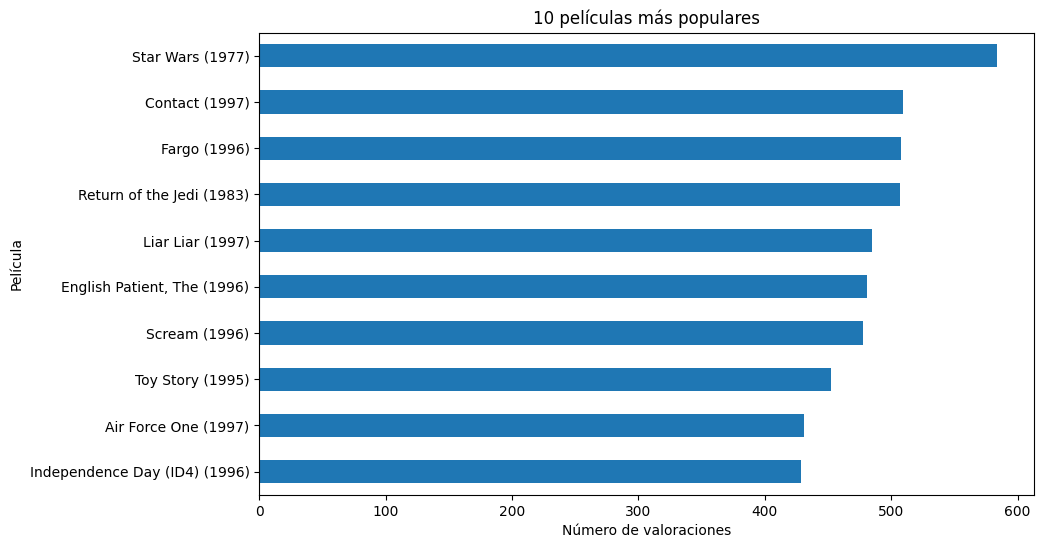

In [10]:
#graficamos

top_populares['count'].sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.xlabel('Número de valoraciones')
plt.ylabel('Película')
plt.title('10 películas más populares')
plt.show()

El sistema basado en popularidad recomienda aquellas películas que han recibido un mayor número de valoraciones. En este caso, Star Wars (1977) ocupa la primera posición con 584 valoraciones, seguida de Contact (1997) y Fargo (1996). Este sistema no tiene en cuenta las preferencias particulares de cada usuario, sino la popularidad general de las películas.

## Filtrado colaborativo basado en usuarios

In [11]:
#matriz usuario-pelicula

user_movie_matrix = data.pivot_table(
    index='user_id',
    columns='title',
    values='rating'
)

user_movie_matrix.head()

title,'Til There Was You (1997),1-900 (1994),101 Dalmatians (1996),12 Angry Men (1957),187 (1997),2 Days in the Valley (1996),"20,000 Leagues Under the Sea (1954)",2001: A Space Odyssey (1968),3 Ninjas: High Noon At Mega Mountain (1998),"39 Steps, The (1935)",...,Yankee Zulu (1994),Year of the Horse (1997),You So Crazy (1994),Young Frankenstein (1974),Young Guns (1988),Young Guns II (1990),"Young Poisoner's Handbook, The (1995)",Zeus and Roxanne (1997),unknown,Á köldum klaka (Cold Fever) (1994)
user_id,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,2.0,5.0,NaN,NaN,3.0,4.0,NaN,NaN,...,NaN,NaN,NaN,5.0,3.0,NaN,NaN,NaN,4.0,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,1.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,2.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Se construye una matriz en la que las filas representan usuarios y las columnas representan películas. Cada celda contiene la valoración realizada por el usuario. Los valores ausentes indican que el usuario no ha valorado esa película.

In [12]:
#similitud entre usuarios

user_similarity = user_movie_matrix.T.corr(
    method='pearson',
    min_periods=5
)

user_similarity.head()

user_id,0,1,2,3,4,5,6,7,8,9,...,934,935,936,937,938,939,940,941,942,943
user_id,,,,,,,,,,,,,,,,,,,,,
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,1.000000,0.160841,0.11278,0.500000,0.420809,0.295410,0.258137,0.692086,-0.102062,...,0.061695,-0.260242,0.386346,0.029000,0.326744,5.343904e-01,0.263289,0.205616,-0.180784,0.067549
2,NaN,0.160841,1.000000,0.06742,0.148522,0.327327,0.446966,0.643675,0.585491,0.242536,...,0.029341,-0.271163,0.214017,0.566724,0.331587,1.380822e-16,-0.011682,-0.062017,0.085960,0.479702
3,NaN,0.112780,0.067420,1.00000,-0.262600,NaN,-0.109109,0.064803,0.291937,NaN,...,NaN,NaN,-0.045162,0.000000,-0.137523,NaN,-0.104678,NaN,-0.011792,NaN
4,NaN,0.500000,0.148522,-0.26260,1.000000,NaN,-0.581318,-0.266632,0.642938,NaN,...,NaN,NaN,-0.203653,NaN,0.375000,NaN,0.850992,NaN,0.412568,NaN


In [13]:
#seleccionamos un usuario

usuario = 196

similares = user_similarity[usuario].drop(
    index=usuario
).dropna()

similares = similares.sort_values(
    ascending=False
)

similares.head(10)

,196
user_id,
277,0.871187
839,0.866025
256,0.801784
460,0.780399
891,0.763763
97,0.755929
402,0.731272
79,0.729756
722,0.720577


In [14]:
#seleccionamos usuarios mas similares

usuarios_similares = similares[
    similares > 0
].head(20)

usuarios_similares

,196
user_id,
277,0.871187
839,0.866025
256,0.801784
460,0.780399
891,0.763763
97,0.755929
402,0.731272
79,0.729756
722,0.720577


In [15]:
#generamos recomendaciones

ratings_similares = user_movie_matrix.loc[
    usuarios_similares.index
]

ratings_ponderados = ratings_similares.mul(
    usuarios_similares,
    axis=0
)

puntuaciones = (
    ratings_ponderados.sum(axis=0) /
    ratings_similares.notna().mul(
        usuarios_similares,
        axis=0
    ).sum(axis=0)
)

In [16]:
#quitamos peliculas que el usuario ya ha valorado

peliculas_vistas = user_movie_matrix.loc[
    usuario
].dropna().index

recomendaciones_usuario = puntuaciones.drop(
    labels=peliculas_vistas,
    errors='ignore'
).dropna()

recomendaciones_usuario = recomendaciones_usuario.sort_values(
    ascending=False
)

recomendaciones_usuario.head(10)

,0
title,
Henry V (1989),5.0
"Young Poisoner's Handbook, The (1995)",5.0
"Hate (Haine, La) (1995)",5.0
Hoop Dreams (1994),5.0
Hotel de Love (1996),5.0
"Apostle, The (1997)",5.0
"Great Escape, The (1963)",5.0
Just Cause (1995),5.0
"Haunted World of Edward D. Wood Jr., The (1995)",5.0


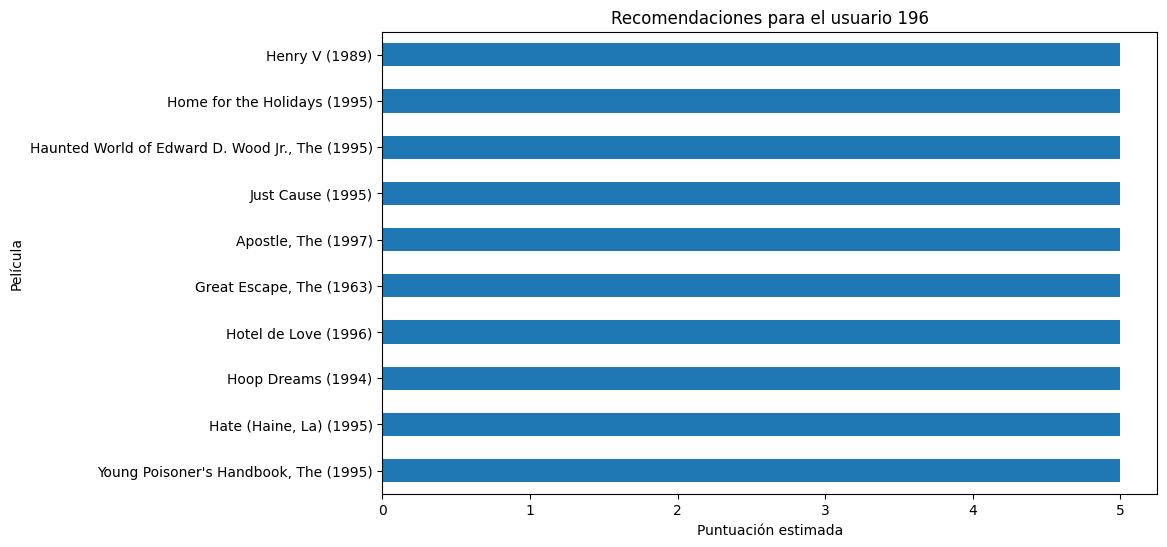

In [17]:
#visualizacion

top_usuario = recomendaciones_usuario.head(10)

top_usuario.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.xlabel('Puntuación estimada')
plt.ylabel('Película')
plt.title('Recomendaciones para el usuario 196')
plt.show()

A diferencia del sistema basado en popularidad, este método proporciona recomendaciones personalizadas. Las películas seleccionadas dependen de las valoraciones realizadas por otros usuarios cuyos gustos presentan una alta similitud con los del usuario 196.

## Filtrado colaborativo basado en ítems

In [18]:
#calculamos similitud entre peliculas

item_similarity = user_movie_matrix.corr(
    method='pearson',
    min_periods=20
)

item_similarity.head()

title,'Til There Was You (1997),1-900 (1994),101 Dalmatians (1996),12 Angry Men (1957),187 (1997),2 Days in the Valley (1996),"20,000 Leagues Under the Sea (1954)",2001: A Space Odyssey (1968),3 Ninjas: High Noon At Mega Mountain (1998),"39 Steps, The (1935)",...,Yankee Zulu (1994),Year of the Horse (1997),You So Crazy (1994),Young Frankenstein (1974),Young Guns (1988),Young Guns II (1990),"Young Poisoner's Handbook, The (1995)",Zeus and Roxanne (1997),unknown,Á köldum klaka (Cold Fever) (1994)
title,,,,,,,,,,,,,,,,,,,,,
'Til There Was You (1997),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1-900 (1994),NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
101 Dalmatians (1996),NaN,NaN,1.00000,-0.04989,NaN,0.048973,0.266928,-0.043407,NaN,NaN,...,NaN,NaN,NaN,0.158840,0.119234,NaN,NaN,NaN,NaN,NaN
12 Angry Men (1957),NaN,NaN,-0.04989,1.00000,NaN,NaN,0.274772,0.178848,NaN,0.457176,...,NaN,NaN,NaN,0.096546,0.068944,NaN,NaN,NaN,NaN,NaN
187 (1997),NaN,NaN,NaN,NaN,1.0,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [19]:
#valoraciones del usuario, seguimos con el 196

valoraciones_usuario = user_movie_matrix.loc[
    usuario
].dropna()

valoraciones_usuario.head(10)

,196
title,
Ace Ventura: Pet Detective (1994),5.0
"Adventures of Priscilla, Queen of the Desert, The (1994)",4.0
"American President, The (1995)",5.0
Babe (1995),5.0
Beautiful Girls (1996),3.0
Being There (1979),5.0
"Birdcage, The (1996)",4.0
Boogie Nights (1997),3.0
Cold Comfort Farm (1995),3.0


In [20]:
#generamos recomendaciones

numerador = item_similarity[
    valoraciones_usuario.index
].mul(
    valoraciones_usuario,
    axis=1
).sum(axis=1)

denominador = item_similarity[
    valoraciones_usuario.index
].abs().sum(axis=1)

recomendaciones_items = numerador / denominador

In [21]:
#eliminamos peliculas que ya ha visto

recomendaciones_items = recomendaciones_items.drop(
    labels=valoraciones_usuario.index,
    errors='ignore'
)

recomendaciones_items = recomendaciones_items.dropna()

recomendaciones_items = recomendaciones_items.sort_values(
    ascending=False
)

recomendaciones_items.head(10)

,0
title,
Hard Rain (1998),5.0
"Crossing Guard, The (1995)",5.0
Once Upon a Time... When We Were Colored (1995),5.0
Keys to Tulsa (1997),5.0
Kull the Conqueror (1997),5.0
Fire Down Below (1997),5.0
That Darn Cat! (1997),5.0
Cats Don't Dance (1997),5.0
Chungking Express (1994),5.0


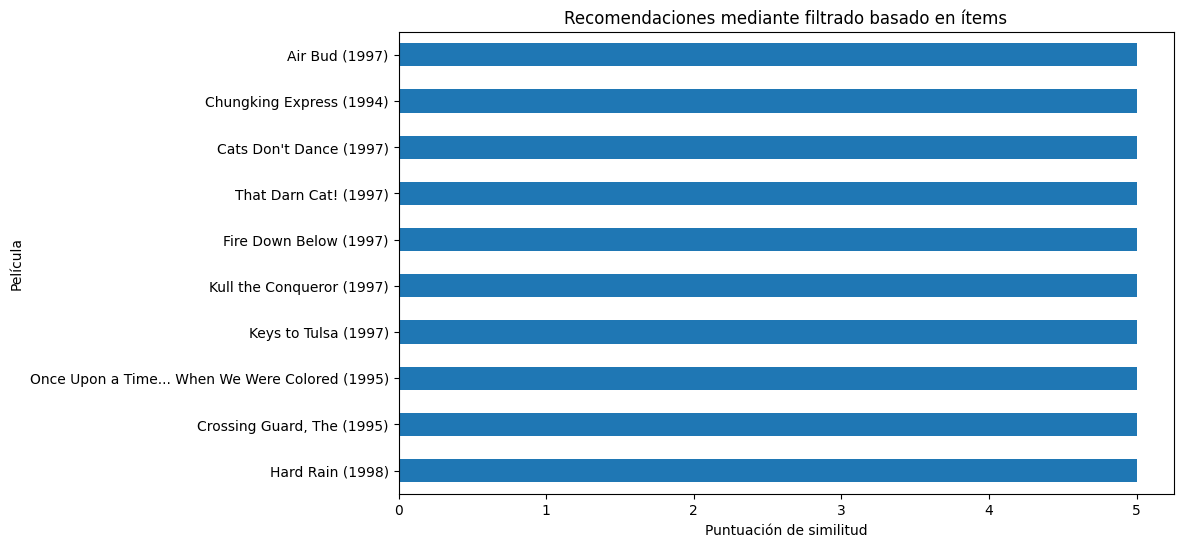

In [22]:
#grafico

top_items = recomendaciones_items.head(10)

top_items.sort_values().plot(
    kind='barh',
    figsize=(10, 6)
)

plt.xlabel('Puntuación de similitud')
plt.ylabel('Película')
plt.title('Recomendaciones mediante filtrado basado en ítems')
plt.show()

## Comparación de los 3 métodos

Se han implementado tres métodos diferentes de recomendación. El sistema basado en popularidad es el más sencillo, ya que recomienda las películas con un mayor número de valoraciones. Su principal ventaja es que puede utilizarse para cualquier usuario, aunque no ofrece recomendaciones personalizadas.

El filtrado colaborativo basado en usuarios ofrece una mayor personalización, ya que identifica usuarios con patrones de valoración similares y utiliza sus preferencias para generar recomendaciones. Sin embargo, su funcionamiento depende de que existan suficientes valoraciones comunes entre los usuarios.

Por su parte, el filtrado colaborativo basado en ítems utiliza la similitud entre películas. Las recomendaciones se generan a partir de las películas que el usuario ya ha valorado y de aquellas que presentan patrones de valoración similares.

En conclusión, el método basado en popularidad resulta adecuado para ofrecer recomendaciones generales, mientras que los métodos colaborativos permiten adaptar las recomendaciones a las preferencias concretas de cada usuario. El filtrado basado en usuarios se centra en encontrar personas con gustos similares, mientras que el filtrado basado en ítems se centra en encontrar películas similares a las que ya han gustado al usuario.